# 7 · Where the search's error comes from

Before a network is put on top of the tile search, this asks where its error is. The search
assumes three things - one rigid motion per tile, going on at the same speed, and that every
change is a motion - and every drawn scene records what really happened on each frame: the
background's scroll, a region scrolling inside the window, a window dragged, a menu opening.
So every client tile at a generated frame N+1 is labelled by what touched it between the
received frame N-2 and N+1, and the search's error is split by label; a recording is labelled
by its kind, `screen` or `video`.

The error is the weighted Y'CbCr squared error the score uses, summed over the region the
client keeps from each tile: it adds up across tiles, so the search's error can be split by
label and each label's share of it read off - a budget, which averages of dB cannot give.

Steps:

1. **Data** - every validation tile, labelled, with the error of repeat and of the search.
2. **The budget** - the search's error by label.
3. **By family** - the labels grouped by what the client could know about them.
4. **What it looks like** - a tile of each of the largest labels.
5. **The search's measurement, against the scenes'** - how far off its motion is on scrolls.

Nothing is trained or exported. Needs: `00_data_preprocess.ipynb` and the sources it read.

A tile's label is the first of these that touched it, in order of how little the frames
before say about it: a menu opening or closing at N+1; one that did between N-2 and N; a
window dragged; a region scrolling; the background scrolling - each motion *starting*
(still from N-2 to N, moving after), *stopping*, *changing speed* (by more than one stream
pixel from half its last motion) or *going on*; video; nothing recorded.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import budget, clips, metrics, models, runs, show, training
from helpers.training import DEVICE

RADIUS, SCALE, SHARPNESS, STRIDE, STILL = 4, 2, 10.0, 2, 0.1   # notebook 3's published search
EVERY = 1        # a sample at every received frame N from N = 2
CACHE = training.CHECKPOINT_DIR / "budget"
SEARCH, INK, MUTED = "#2a78d6", "#3d3d3a", "#8a8a85"   # the reference palette's slot 1, ink, muted
SEED = 0
training.seed_everything(SEED)

## 1. Data

Every validation source rebuilt from the manifest and cut into the client's tiles, at every
received frame N: the tile's labels (`budget.events`), and the summed error of repeat and of
the published search (`budget.errors`). The tiles counted are the **active** ones - the
search's gate is open (something moved from N-2 to N) or N+1 differs from N - since on the
others every method returns N and N is right.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
search = models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, 1 / runs.received_every(manifest), still=STILL).to(DEVICE).eval()

CACHE.mkdir(parents=True, exist_ok=True)
path = CACHE / f"val_r{RADIUS}_s{STRIDE}_e{EVERY}.pkl"
started = time.time()
if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
    table = pickle.loads(path.read_bytes())
else:
    table = budget.load(manifest, "val", search, EVERY)
    path.write_bytes(pickle.dumps(table))
error, pixels = table["error"], table["pixels"]
active = table["changed"] | table["moving"]
print(f"{len(active)} tiles from {len(set(table['source']))} clips in {time.time() - started:.0f}s: "
      f"{active.sum()} active ({table['moving'].sum()} moving from N-2 to N, {table['changed'].sum()} changed to N+1)")
print(f"the search's error outside the active tiles: {error['search'][~active].sum() / error['search'].sum():.2%} of all of it")

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
19374 tiles from 232 clips in 0s: 10999 active (10780 moving from N-2 to N, 6272 changed to N+1)
the search's error outside the active tiles: 0.05% of all of it


## 2. The budget

Per label, over the active tiles: how many, their share of the search's whole error, and the
mean wPSNR of repeat and of the search there.

In [3]:
labels = np.array(table["label"])
order = [label for label in budget.LABELS if (labels[active] == label).any()]
total = error["search"][active].sum()
rows = []
for label in order + ["all active"]:
    chosen = active & ((labels == label) if label != "all active" else True)
    rows.append({"label": label, "tiles": int(chosen.sum()), "of the error": error["search"][chosen].sum() / total,
                 "repeat dB": budget.wpsnr(error["repeat"][chosen], pixels[chosen]).mean(),
                 "search dB": budget.wpsnr(error["search"][chosen], pixels[chosen]).mean()})

print(f"{'active tiles, by label':<34}{'tiles':>7}{'of the error':>14}{'repeat dB':>11}{'search dB':>11}")
for row in rows:
    if row["label"] == "all active":
        print("-" * 77)
    print(f"{row['label']:<34}{row['tiles']:7}{row['of the error']:14.1%}{row['repeat dB']:11.2f}{row['search dB']:11.2f}")

active tiles, by label              tiles  of the error  repeat dB  search dB
menu opens or closes at N+1             5          0.1%      28.95      28.94
menu opened or closed before N         13          0.0%      76.50      74.36
drag: starts                           18          0.2%      30.84      29.93
drag: stops                            24          0.2%      57.55      44.46
drag: changes speed                   375          6.5%      29.55      30.99
drag: goes on                          74          0.7%      28.06      32.94
region: starts                         18          0.1%      29.07      29.07
region: stops                          31          0.1%      91.70      70.01
region: changes speed                 114          1.3%      29.13      29.05
region: goes on                        24          0.2%      28.93      29.59
scroll: starts                        181          6.0%      23.68      23.68
scroll: stops                         245          4.7%      72.

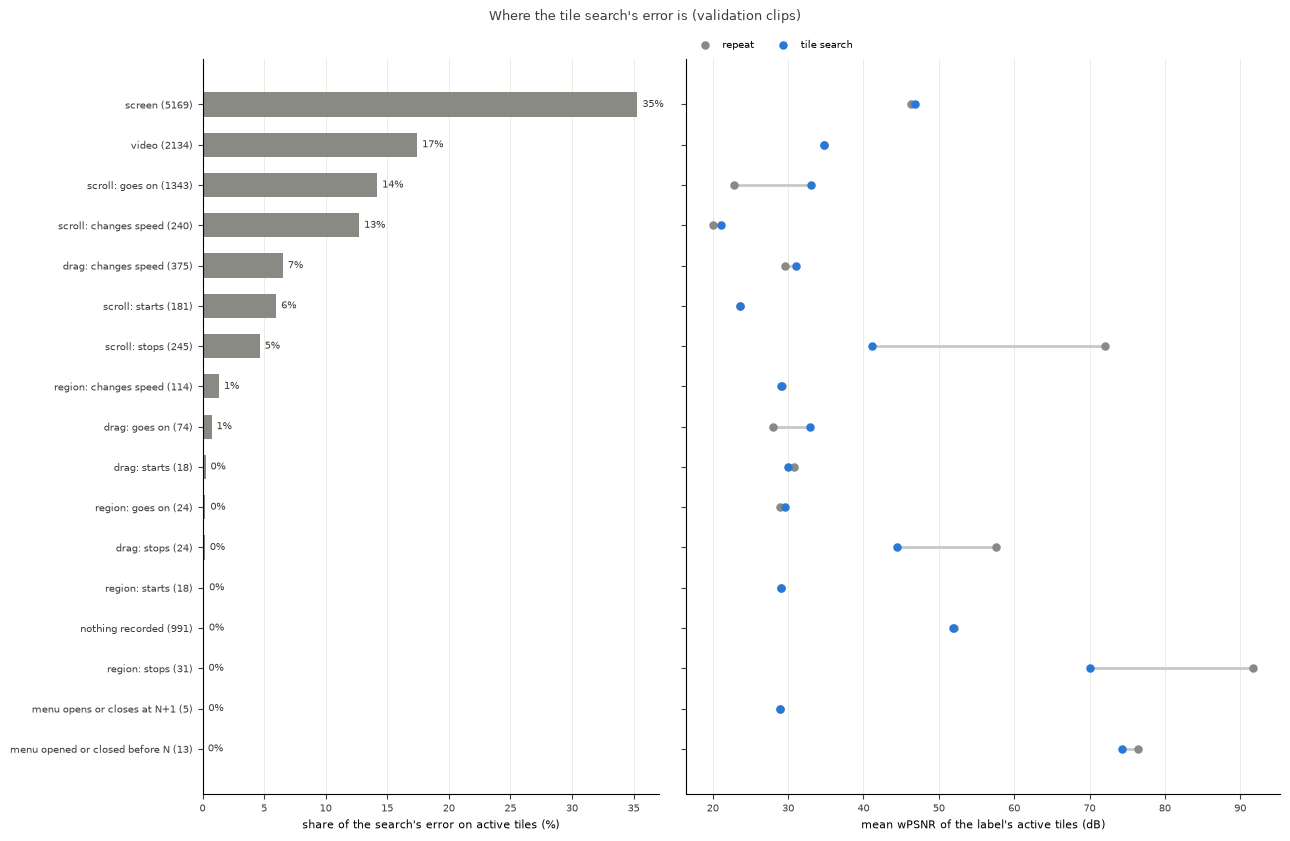

In [4]:
"""The budget drawn: left, each label's share of the search's error; right, the mean wPSNR of
repeat and of the search on its active tiles. Labels in order of their share."""

shown = sorted([row for row in rows if row["label"] != "all active"], key=lambda row: row["of the error"])
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 0.42 * len(shown) + 1.4), sharey=True,
                                  gridspec_kw={"width_ratios": (1, 1.3)})
positions = np.arange(len(shown))
left.barh(positions, [row["of the error"] * 100 for row in shown], height=0.6, color=MUTED)
for y, row in zip(positions, shown):
    left.text(row["of the error"] * 100 + 0.4, y, f"{row['of the error']:.0%}", va="center", fontsize=7, color=INK)
left.set_yticks(positions, [f"{row['label']} ({row['tiles']})" for row in shown], fontsize=8)
left.set_xlabel("share of the search's error on active tiles (%)", fontsize=8)
right.hlines(positions, [row["repeat dB"] for row in shown], [row["search dB"] for row in shown], color="#c9c9c4", lw=2)
right.scatter([row["repeat dB"] for row in shown], positions, s=26, color=MUTED, label="repeat", zorder=3)
right.scatter([row["search dB"] for row in shown], positions, s=26, color=SEARCH, label="tile search", zorder=3)
right.set_xlabel("mean wPSNR of the label's active tiles (dB)", fontsize=8)
right.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
for ax in (left, right):
    ax.tick_params(labelsize=7, colors=INK)
    ax.grid(axis="x", color="#e6e6e3", lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("Where the tile search's error is (validation clips)", fontsize=9, color=INK)
fig.tight_layout()
plt.show()

## 3. By family

The labels grouped by what the client could know about them before N+1 arrives:

- **unannounced** - a menu opening or closing at N+1, a motion starting: nothing before N+1
  shows it. No model can learn it from the frames; the client's own input could;
- **announced change** - a menu that opened or closed between N-2 and N: the search reads a
  change as a motion. The frames show it is not one;
- **part of the tile moves** - a dragged window, a scrolled region: the motion is in the
  frames, for part of the tile only;
- **the whole tile moves** - the background scroll: one motion is right; what it misses is
  when it stops or changes speed;
- **video**, and **nothing recorded** - codec noise, and what the scene does not label.

In [5]:
FAMILIES = {
    "unannounced": lambda label: label in ("menu opens or closes at N+1",) or label.endswith(": starts"),
    "announced change": lambda label: label == "menu opened or closed before N",
    "part of the tile moves": lambda label: label.startswith(("drag", "region")) and not label.endswith(": starts"),
    "whole tile moves": lambda label: label.startswith("scroll") and not label.endswith(": starts"),
    "screen": lambda label: label == "screen",
    "video": lambda label: label == "video",
    "nothing recorded": lambda label: label == "nothing recorded",
}
family = np.array([next(name for name, test in FAMILIES.items() if test(label)) for label in labels])
print(f"{'active tiles, by family':<28}{'tiles':>7}{'of the error':>14}{'repeat dB':>11}{'search dB':>11}")
for name in FAMILIES:
    chosen = active & (family == name)
    if not chosen.any():
        continue
    print(f"{name:<28}{chosen.sum():7}{error['search'][chosen].sum() / total:14.1%}"
          f"{budget.wpsnr(error['repeat'][chosen], pixels[chosen]).mean():11.2f}"
          f"{budget.wpsnr(error['search'][chosen], pixels[chosen]).mean():11.2f}")

active tiles, by family       tiles  of the error  repeat dB  search dB
unannounced                     222          6.4%      24.82      24.74
announced change                 13          0.0%      76.50      74.36
part of the tile moves          642          9.1%      33.33      33.21
whole tile moves               1828         31.6%      29.02      32.59
screen                         5169         35.3%      46.27      46.78
video                          2134         17.4%      34.72      34.78
nothing recorded                991          0.1%      51.96      51.91


## 4. What it looks like

For the four labels with the most error, the tile where the search does worst: the change
from N to N+1, and the error of repeat and of the search.

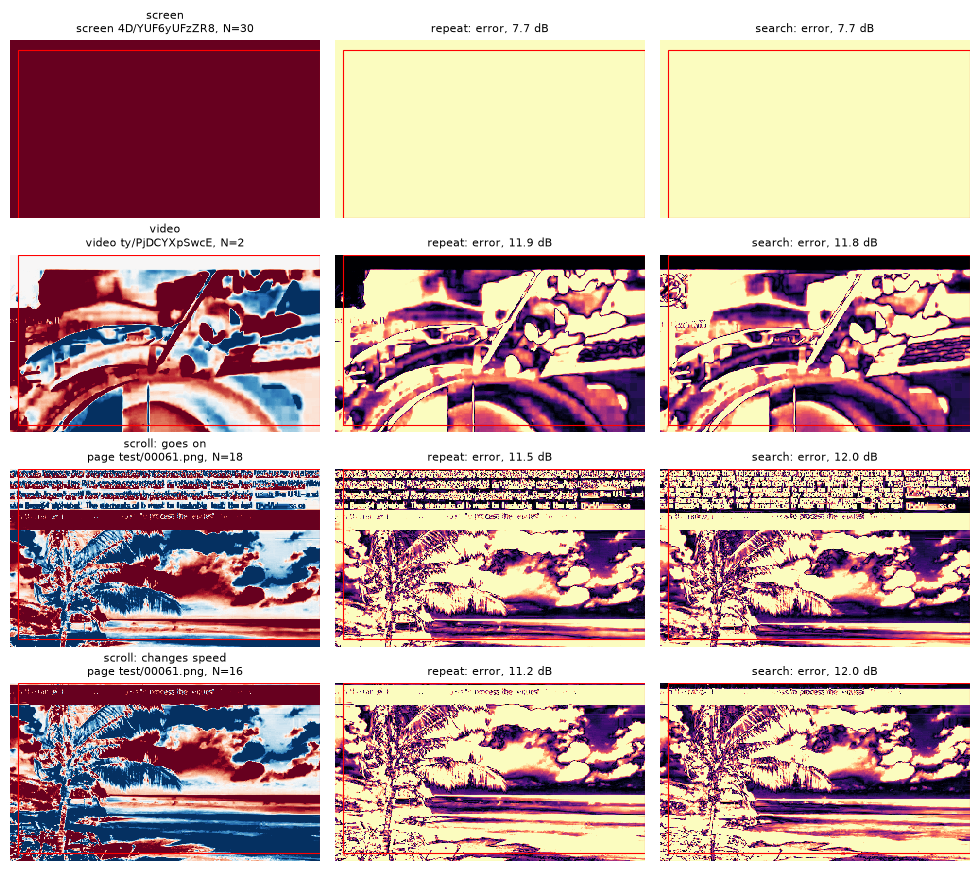

changes and errors full colour at 48 luma levels


In [6]:
largest = [row["label"] for row in sorted(rows[:-1], key=lambda row: -row["of the error"])[:4]]
columns = ["change N -> N+1", "repeat: error", "search: error"]
fig, axes = plt.subplots(len(largest), len(columns), figsize=(3.3 * len(columns), 2.2 * len(largest)), squeeze=False)
sources = manifest["splits"]["val"]["sources"]
step = runs.received_every(manifest)
for row, label in enumerate(largest):
    chosen = np.flatnonzero(active & (labels == label))
    index = chosen[np.argmax(error["search"][chosen])]
    source = sources[table["source"][index]]
    stream = clips.rebuild(source, manifest)
    layout, size = clips.plan(stream.shape[2], stream.shape[1])
    ix, iy = layout[table["tile"][index]][:2]
    n = table["frame"][index]
    window = stream[[n - step, n, n + 1], iy:iy + size[0], ix:ix + size[1]]
    previous, current, target = training.to_tensor(window[None]).unbind(1)
    box = tuple(table["box"][index])
    found, made = budget.errors(search, previous, current, target, box, keep=True)
    ax = axes[row]
    show.change(ax[0], current, target, f"{label}\n{source['kind']} {source.get('video', source['file'])[-14:]}, N={n}", box)
    for column, name in enumerate(("repeat", "search"), start=1):
        score = metrics.wpsnr(clips.kept(made[name], box), clips.kept(target, box))
        show.error(ax[column], made[name], target, f"{name}: error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()
print(f"changes and errors full colour at {show.LEVELS} luma levels")

## 5. The search's measurement, against the scenes'

For the drawn scrolls - even steady ones, where nothing stops or changes speed - the search's
motion from N-2 to N set beside the scroll the scene recorded, by how far the content really
moved. The motions are notebook 6's, kept per tile.

In [7]:
from helpers import history

kept = history.restore(training.CHECKPOINT_DIR / "history" / "val_r4_s2_w8_d3_e1.npz")
where = {key: i for i, key in enumerate(zip(kept["source"], kept["frame"], kept["tile"]))}
scale = manifest["scale"]
for label in ("scroll: goes on", "scroll: changes speed"):
    chosen = [i for i in np.flatnonzero(active & (labels == label))
              if (table["source"][i], table["frame"][i], table["tile"][i]) in where]
    true, found, wide = [], [], []
    for i in chosen:
        scroll = np.array(sources[table["source"][i]]["scene"]["scroll"], float)
        n = table["frame"][i]
        true.append(-(scroll[n] - scroll[n - step]) / scale)          # content moves against the scroll
        j = where[(table["source"][i], n, table["tile"][i])]
        found.append(kept["motion"][j, 0])
        wide.append(kept["wide"][j, 0])
    true, found, wide = map(np.array, (true, found, wide))
    searched = error["search"][chosen]
    speed = np.abs(true).max(1)
    print(f"\n{label}: {len(chosen)} tiles with history")
    for low, high in ((0, 2), (2, 4), (4, 8), (8, 12), (12, 99)):
        k = (speed >= low) & (speed < high)
        print(f"  moved {low:>2}-{high:<2} px from N-2 to N: {k.sum():4} tiles, {searched[k].sum() / searched.sum():5.1%} of the "
              f"label's error; search off by {np.median(np.linalg.norm(found[k] - true[k], axis=1)):5.2f} px (median), "
              f"±16 px search by {np.median(np.linalg.norm(wide[k] - true[k], axis=1)):5.2f}")


scroll: goes on: 1321 tiles with history
  moved  0-2  px from N-2 to N:  149 tiles,  7.9% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50
  moved  2-4  px from N-2 to N:  420 tiles, 19.0% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50
  moved  4-8  px from N-2 to N:  507 tiles, 26.5% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50
  moved  8-12 px from N-2 to N:  140 tiles, 10.0% of the label's error; search off by  1.50 px (median), ±16 px search by  0.46
  moved 12-99 px from N-2 to N:  105 tiles, 36.6% of the label's error; search off by 16.01 px (median), ±16 px search by  1.00

scroll: changes speed: 236 tiles with history
  moved  0-2  px from N-2 to N:    6 tiles,  0.6% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50
  moved  2-4  px from N-2 to N:    8 tiles,  4.2% of the label's error; search off by  0.99 px (median), ±16 px search by  0.91
  moved  4-8  p

## What it says

- **A third of the search's error is on screen recordings** (35%), a third on drawn tiles that
  move whole (32%: scrolls and pans), a sixth on video (17%), and less on drawn tiles that move in
  part (9%: a dragged window, a scrolled region) and on what starts without warning (6%).
- **On the recordings the search is barely above repeat.** Over their active tiles, screens 46.78
  dB against repeat's 46.27, video 34.78 against 34.72 - where on drawn tiles that move whole it is
  32.59 against 29.02. Whatever a screen changes between two frames, one motion of the tile
  reproduces little more of it than the frame before.
- **Drawn whole-tile motion is part measurement, part prediction.** Steady scrolls hold 14% of the
  error, and there the search's motion is wrong: half a stream pixel off below 8 px, and for the
  fastest (over 12 px between received frames: 37% of that label's error) past its ±8 px reach and
  off by 16 px, where a ±16 px search is off by 1.0. Speed changes (13%) and starts (6%) are what
  the frames before do not announce; at a stop the search scores 41.19 dB where repeat has 72.12.
- **Where part of a drawn tile moves, the search is under repeat** (33.21 against 33.33): one
  motion for the tile moves the still part with the window, or the window with the still part.
- **What starts without warning is out of reach** (6%): the search is no better than repeat there
  (24.74 against 24.82). Nothing in N−2 and N shows it; the client's own input would.

So on the drawn scenes the order still is: measure the motion better - a wider, sub-pixel search
with a stop decision (notebook 8) - then a motion per part of the tile. On the recordings one
motion per tile adds little over repeat; notebook 11 measures why - most of their change is not
one motion of the tile.